In [1]:
import pandas as pd


In [2]:
import numpy as np

In [3]:
on = pd.read_excel("data/raw/oncampus.xlsx")
off = pd.read_excel("data/raw/offcampus.xlsx")

print("On-campus shape:", on.shape)
print("Off-campus shape:", off.shape)

On-campus shape: (905, 84)
Off-campus shape: (3890, 83)


In [4]:
# List identifier columns to remove
id_cols = ["Name", "Admission No"]

# Drop them if they exist in the datasets
on = on.drop(columns=[c for c in id_cols if c in on.columns])
off = off.drop(columns=[c for c in id_cols if c in off.columns])

print("On-campus columns after dropping IDs:", len(on.columns))
print("Off-campus columns after dropping IDs:", len(off.columns))

On-campus columns after dropping IDs: 84
Off-campus columns after dropping IDs: 83


In [5]:
# Convert headers to string and strip spaces
on.columns = on.columns.astype(str).str.strip()
off.columns = off.columns.astype(str).str.strip()

# Keep only columns present in both files
common = [c for c in on.columns if c in off.columns]
print("Number of shared sessions:", len(common))

on = on[common]
off = off[common]

Number of shared sessions: 83


In [6]:
def clean_codes(df):
    df = df.copy()
    df = df.apply(lambda s: s.astype(str).str.strip().str.upper())
    df = df.replace({"PRESENT": "P", "ABSENT": "A", "NAN": np.nan, "": np.nan, "NONE": np.nan})
    return df

on = clean_codes(on)
off = clean_codes(off)

# Remove duplicate rows and columns
on = on.drop_duplicates().T.drop_duplicates().T
off = off.drop_duplicates().T.drop_duplicates().T

# Update common sessions list after dropping duplicates
common = [c for c in on.columns if c in off.columns]
on = on[common]
off = off[common]

In [7]:
mapping = {"P": 1, "A": 0}

on_enc = on.apply(lambda s: s.map(mapping))
off_enc = off.apply(lambda s: s.map(mapping))

# Assign group target label
on_enc["Residence"] = 1
off_enc["Residence"] = 0

# Combine into master DataFrame
df = pd.concat([on_enc, off_enc], ignore_index=True)

print("Combined dataset shape:", df.shape)
print("Target distribution:\n", df["Residence"].value_counts(normalize=True))

Combined dataset shape: (4795, 75)
Target distribution:
 Residence
0    0.811262
1    0.188738
Name: proportion, dtype: float64


In [8]:
# Compute summary features
session_cols = [c for c in df.columns if c != "Residence"]
df["Attendance_Rate"] = df[session_cols].mean(axis=1)
df["Total_Absences"] = (df[session_cols] == 0).sum(axis=1)

# Remove students who were absent for all sessions
active = df[df["Attendance_Rate"] > 0].copy().reset_index(drop=True)

print("Active students remaining:", len(active))

# Save processed file ready for modeling
import os
os.makedirs("data/processed", exist_ok=True)
active.to_csv("data/processed/attendance_active_only.csv", index=False)

print("Successfully saved data/processed/attendance_active_only.csv!")

Active students remaining: 2452
Successfully saved data/processed/attendance_active_only.csv!


In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load cleaned active dataset
df = pd.read_csv("data/processed/attendance_active_only.csv")

# Separate session features (X) from group target (y)
feature_cols = [c for c in df.columns if c not in ["Attendance_Rate", "Total_Absences", "Residence"]]
X = df[feature_cols]
y = df["Residence"]

# Stratified 80/20 train/test split to preserve group proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} students")
print(f"Test set size: {X_test.shape[0]} students")
print("Target distribution in training set:\n", y_train.value_counts(normalize=True).round(3))

Training set size: 1961 students
Test set size: 491 students
Target distribution in training set:
 Residence
0    0.753
1    0.247
Name: proportion, dtype: float64


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, roc_auc_score

# 1. Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    class_weight='balanced',
    random_state=42
)

# 2. Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    class_weight='balanced',
    random_state=42
)

# Perform 5-Fold Cross-Validation (Scoring: ROC-AUC)
dt_cv = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='roc_auc').mean()
rf_cv = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='roc_auc').mean()

print(f"Decision Tree 5-Fold CV ROC-AUC: {dt_cv:.3f}")
print(f"Random Forest 5-Fold CV ROC-AUC: {rf_cv:.3f}\n")

# Train models on training set and test on held-out data
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("=== Decision Tree Performance (Test Set) ===")
print(classification_report(y_test, y_pred_dt, target_names=["Off-campus (0)", "On-campus (1)"]))
print("ROC-AUC:", round(roc_auc_score(y_test, dt_model.predict_proba(X_test)[:, 1]), 3))

print("\n=== Random Forest Performance (Test Set) ===")
print(classification_report(y_test, y_pred_rf, target_names=["Off-campus (0)", "On-campus (1)"]))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]), 3))

Decision Tree 5-Fold CV ROC-AUC: 0.690
Random Forest 5-Fold CV ROC-AUC: 0.787

=== Decision Tree Performance (Test Set) ===
                precision    recall  f1-score   support

Off-campus (0)       0.84      0.84      0.84       369
 On-campus (1)       0.51      0.51      0.51       122

      accuracy                           0.76       491
     macro avg       0.68      0.67      0.67       491
  weighted avg       0.76      0.76      0.76       491

ROC-AUC: 0.74

=== Random Forest Performance (Test Set) ===
                precision    recall  f1-score   support

Off-campus (0)       0.87      0.82      0.85       369
 On-campus (1)       0.54      0.62      0.58       122

      accuracy                           0.77       491
     macro avg       0.70      0.72      0.71       491
  weighted avg       0.79      0.77      0.78       491

ROC-AUC: 0.805


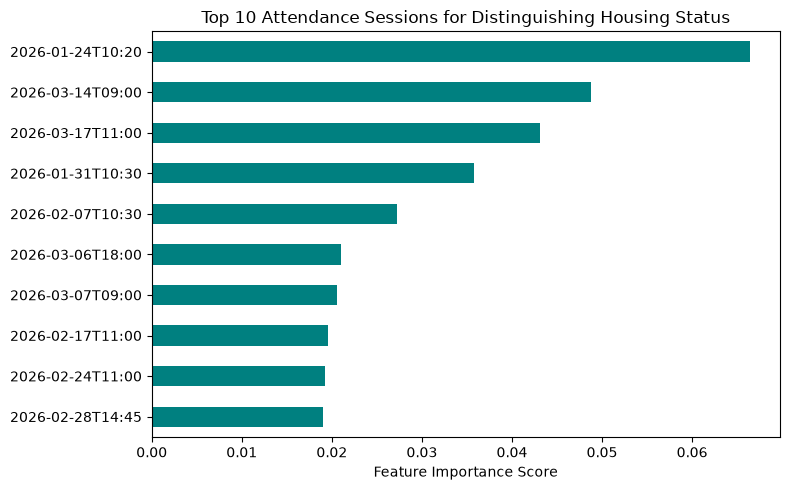

Top 5 Predictive Sessions:
2026-01-24T10:20    0.066436
2026-03-14T09:00    0.048757
2026-03-17T11:00    0.043067
2026-01-31T10:30    0.035799
2026-02-07T10:30    0.027273
dtype: float64


In [11]:
import matplotlib.pyplot as plt

# Extract feature importances
importances = pd.Series(rf_model.feature_importances_, index=feature_cols)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top_features.sort_values().plot(kind="barh", color="teal")
plt.xlabel("Feature Importance Score")
plt.title("Top 10 Attendance Sessions for Distinguishing Housing Status")
plt.tight_layout()
plt.show()

print("Top 5 Predictive Sessions:")
print(top_features.head(5))